In [1]:
#Getting my libraries ready for handling my work
import pandas as pd
import numpy as np
df = pd.read_csv("StudentsPerformance.csv")

In [2]:
print(df.shape)

(1000, 8)


In [3]:
#Exploring the data information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [4]:
#Checking for null values
print(df.isnull().sum())

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


In [5]:
#checking for duplicates to ensure data quality
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


In [6]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [7]:
for col in df.select_dtypes(include="str"):
    print(col, df[col].unique())

gender <StringArray>
['female', 'male']
Length: 2, dtype: str
race/ethnicity <StringArray>
['group B', 'group C', 'group A', 'group D', 'group E']
Length: 5, dtype: str
parental level of education <StringArray>
[ 'bachelor's degree',       'some college',    'master's degree',
 'associate's degree',        'high school',   'some high school']
Length: 6, dtype: str
lunch <StringArray>
['standard', 'free/reduced']
Length: 2, dtype: str
test preparation course <StringArray>
['none', 'completed']
Length: 2, dtype: str


In [8]:
df.columns = (df.columns.str.strip().str.lower()
             .str.replace("/", "_").str.replace(" ","_"))

In [9]:
df.info()

cat_cols = ["gender", "race_ethnicity", "parental_level_of_education", "lunch", "test_preparation_course"]

for col in cat_cols:
    print(f"\n{col}")
    print(df[col].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race_ethnicity               1000 non-null   str  
 2   parental_level_of_education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test_preparation_course      1000 non-null   str  
 5   math_score                   1000 non-null   int64
 6   reading_score                1000 non-null   int64
 7   writing_score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB

gender
gender
female    518
male      482
Name: count, dtype: int64

race_ethnicity
race_ethnicity
group C    319
group D    262
group B    190
group E    140
group A     89
Name: count, dtype: int64

parental_level_of_education
parental_level_of_education
some college          226
associate's deg

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
num_cols = ["math_score", "reading_score", "writing_score"]

<function matplotlib.pyplot.show(close=None, block=None)>

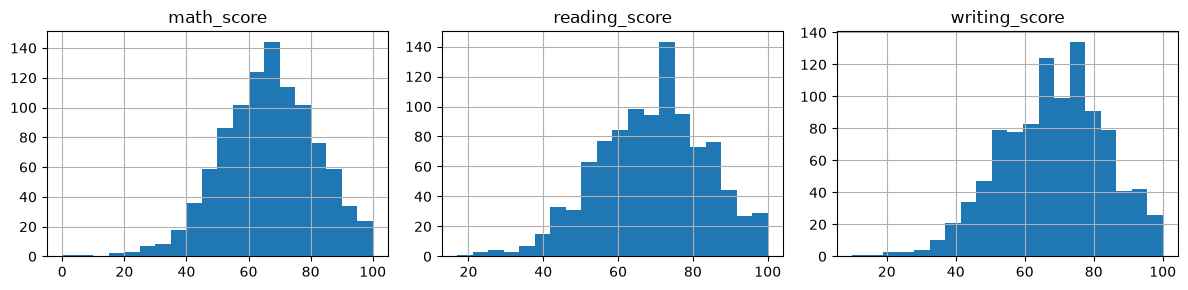

In [12]:
num_cols =  ["math_score", "reading_score", "writing_score"]
df[num_cols].hist(bins=20, figsize=(12, 3), layout=(1, 3))
plt.tight_layout(); plt.show

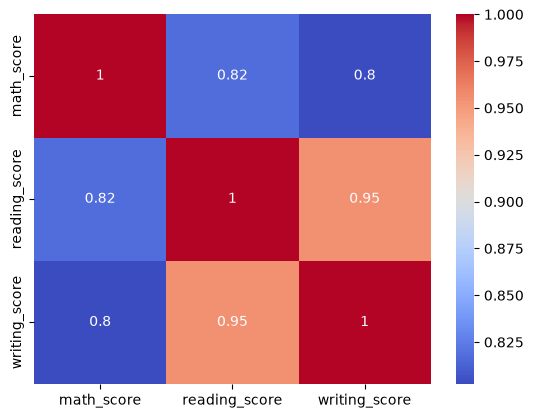

In [13]:
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm")
plt.show()

In [14]:
for col in cat_cols:
    print(df.groupby(col)["math_score"].mean().round(1).sort_values(), "\n")

gender
female    63.6
male      68.7
Name: math_score, dtype: float64 

race_ethnicity
group A    61.6
group B    63.5
group C    64.5
group D    67.4
group E    73.8
Name: math_score, dtype: float64 

parental_level_of_education
high school           62.1
some high school      63.5
some college          67.1
associate's degree    67.9
bachelor's degree     69.4
master's degree       69.7
Name: math_score, dtype: float64 

lunch
free/reduced    58.9
standard        70.0
Name: math_score, dtype: float64 

test_preparation_course
none         64.1
completed    69.7
Name: math_score, dtype: float64 



In [15]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [16]:
target = "math_score"
cat_cols = ["gender", "race_ethnicity", "parental_level_of_education", "lunch", "test_preparation_course"]
score_cols = ["reading_score", "writing_score"]

In [17]:
features_A = cat_cols
features_B = cat_cols + score_cols

y = df[target]

In [18]:
train_idx, test_idx = train_test_split(
    df.index, test_size=0.2, random_state=42
)

XA_train, XA_test = df.loc[train_idx, features_A], df.loc[test_idx, features_A]
XB_train, XB_test = df.loc[train_idx, features_B], df.loc[test_idx, features_B]
y_train, y_test = y.loc[train_idx], y.loc[test_idx]

print(XA_train.shape, XA_test.shape)
print(XB_train.shape, XB_test.shape)

(800, 5) (200, 5)
(800, 7) (200, 7)


In [19]:
preprocess_A = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown= "ignore"), cat_cols)
])
preprocess_B = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), score_cols)
])

In [20]:
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_validate

In [21]:
models ={
    "Dummy (mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42)
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)

setups = [
    ("A (background only)", preprocess_A, XA_train),
    ("B (background + scores)", preprocess_B, XB_train),
]

rows = []
for set_name, prep, X_tr in setups:
    for model_name, model in models.items():
        pipe = Pipeline([("prep", prep), ("model", model)])
        scores = cross_validate(
            pipe, X_tr, y_train, cv=cv,
            scoring=("r2", "neg_root_mean_squared_error", "neg_mean_absolute_error")
        )
        rows.append({
            "features": set_name,
            "model": model_name,
            "R2": scores["test_r2"].mean(),
            "RMSE": -scores["test_neg_root_mean_squared_error"].mean(),
            "MAE": -scores["test_neg_mean_absolute_error"].mean(),
        })

results = pd.DataFrame(rows).round(3)
results

,features,model,R2,RMSE,MAE
0,A (background only),Dummy (mean),-0.007,15.026,11.963
1,A (background only),Linear Regression,0.243,13.018,10.616
2,A (background only),Random Forest,0.033,14.707,11.894
3,B (background + scores),Dummy (mean),-0.007,15.026,11.963
4,B (background + scores),Linear Regression,0.869,5.406,4.342
5,B (background + scores),Random Forest,0.838,6.010,4.819


In [22]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

def tune(prep, X_tr, model, param_grid):
    pipe = Pipeline([("prep", prep), ("model", model)])
    gs = GridSearchCV(pipe, param_grid, cv=cv,
                     scoring="neg_root_mean_squared_error", n_jobs=-1)
    gs.fit(X_tr, y_train)
    return gs

ridge_grid = {"model__alpha": [0.01, 0.1, 1, 3, 10, 30, 100]}
rf_grid = {
    "model__max_depth": [3, 5, 8, None],
    "model__min_samples_leaf": [1, 5, 10,20]
}

results_tuned ={}
for name, prep, X_tr in [("A", preprocess_A, XA_train), ("B", preprocess_B, XB_train)]:
    r = tune(prep, X_tr, Ridge(), ridge_grid)
    f = tune(prep, X_tr, RandomForestRegressor(n_estimators=200, random_state=42), rf_grid)
    results_tuned[name] = {"ridge": r, "rf": f}
    print(f"Model {name}")
    print(" Ridge best:", r.best_params_, "RMSE:", round(-r.best_score_, 3))
    print("  RF best:  ", f.best_params_, "RMSE:", round(-f.best_score_, 3)) 
    

Model A
 Ridge best: {'model__alpha': 10} RMSE: 13.011
  RF best:   {'model__max_depth': 5, 'model__min_samples_leaf': 10} RMSE: 13.257
Model B
 Ridge best: {'model__alpha': 3} RMSE: 5.404
  RF best:   {'model__max_depth': 8, 'model__min_samples_leaf': 1} RMSE: 5.968


In [23]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import joblib

final_A = results_tuned["A"]["ridge"].best_estimator_
final_B = results_tuned["B"]["ridge"].best_estimator_

def evaluate(model, X_te, y_te, label):
    pred = model.predict(X_te)
    print(f"{label}: R2={r2_score(y_te, pred):.3f} | "
         f"RMSE={np.sqrt(mean_squared_error(y_te, pred)):.3f} | "
         f"MAE={mean_absolute_error(y_te, pred):.3f}")
    return pred

pred_A = evaluate(final_A, XA_test, y_test, "Model A (test)")
pred_B = evaluate(final_B, XB_test, y_test, "Model B (test)")

Model A (test): R2=0.176 | RMSE=14.164 | MAE=11.286
Model B (test): R2=0.881 | RMSE=5.386 | MAE=4.206


In [24]:
print(results_tuned.keys())
print(results_tuned["A"].keys())

dict_keys(['A', 'B'])
dict_keys(['ridge', 'rf'])


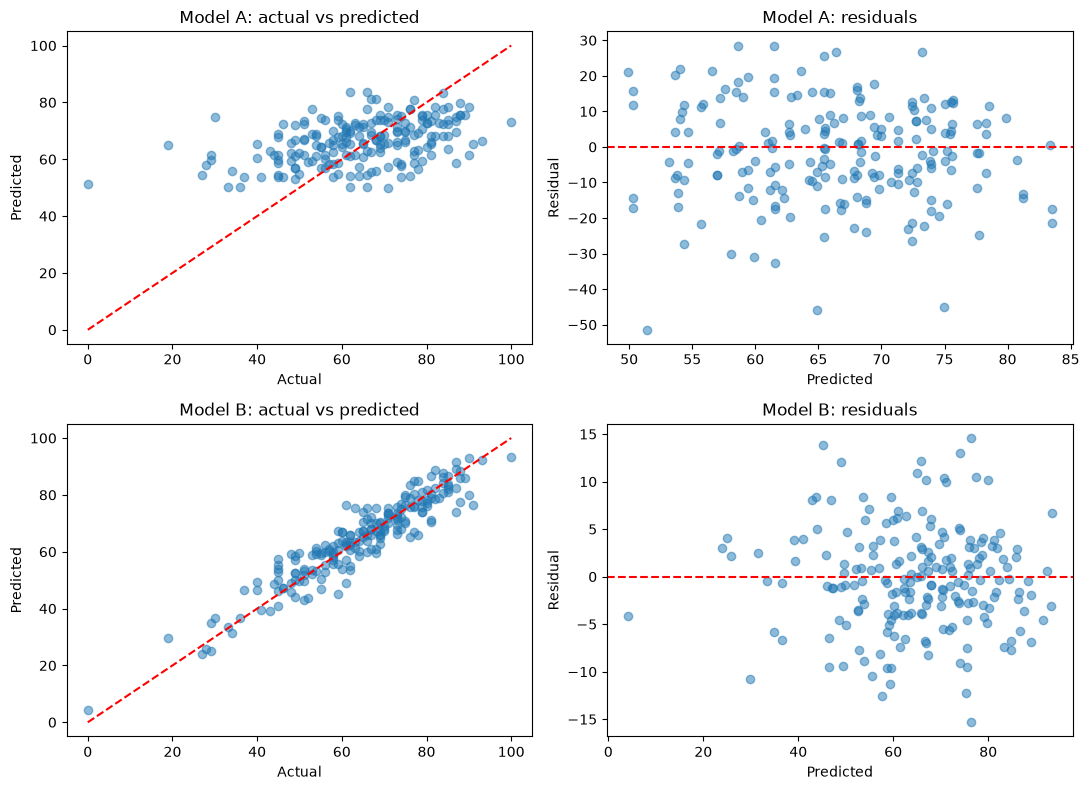

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for i, (pred, label) in enumerate([(pred_A, "Model A"), (pred_B, "Model B")]):
    resid = y_test - pred
    axes[i, 0].scatter(y_test, pred, alpha=0.5)
    axes[i, 0].plot([0, 100], [0, 100], "r--")
    axes[i, 0].set(title=f"{label}: actual vs predicted",
                   xlabel="Actual", ylabel="Predicted")
    axes[i, 1].scatter(pred, resid, alpha=0.5)
    axes[i, 1].axhline(0, color="r", linestyle="--")
    axes[i, 1].set(title=f"{label}: residuals",
                   xlabel="Predicted", ylabel="Residual")
plt.tight_layout(); plt.show()

In [26]:
for name, model in [("A", final_A), ("B", final_B)]:
    names = model.named_steps["prep"].get_feature_names_out()
    coefs = pd.Series(model.named_steps["model"].coef_, index=names)
    print(f"\nModel {name}: top coefficients")
    print(coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(8).round(2))


Model A: top coefficients
cat__race_ethnicity_group E                           5.91
cat__lunch_standard                                   5.61
cat__lunch_free/reduced                              -5.61
cat__parental_level_of_education_high school         -3.36
cat__parental_level_of_education_bachelor's degree    3.32
cat__test_preparation_course_none                    -2.87
cat__test_preparation_course_completed                2.87
cat__race_ethnicity_group B                          -2.40
dtype: float64

Model B: top coefficients
num__writing_score                   10.40
cat__gender_female                   -6.43
cat__gender_male                      6.43
cat__race_ethnicity_group E           3.97
num__reading_score                    3.83
cat__lunch_free/reduced              -1.78
cat__lunch_standard                   1.78
cat__test_preparation_course_none     1.56
dtype: float64


In [27]:
joblib.dump(final_A, "model_A_background.joblib")
joblib.dump(final_B, "model_B_with_scores.joblib")

# Example: reload and predict for a new student
loaded_B = joblib.load("model_B_with_scores.joblib")
new_student = pd.DataFrame([{
    "gender": "female", "race_ethnicity": "group B",
    "parental_level_of_education": "bachelor's degree",
    "lunch": "standard", "test_preparation_course": "completed",
    "reading_score": 75, "writing_score": 78,
}])
print(loaded_B.predict(new_student))

[66.55462162]
